# Лабораторная работа № 1. Регрессия

**Цель:** предсказание оценки качества вина по физико-химическим показателям и сравнение
линейной регрессии, случайного леса и градиентного бустинга с константным baseline.

**Данные:** Wine Quality, красное и белое вино. **Метрики:** RMSE и MAE.
Минимальный порог по заданию: RMSE < 0.70.

**Источники:** [материалы курса](https://github.com/lesopylka/ml_course_mai),
[Wine Quality — UCI](https://archive.ics.uci.edu/dataset/186/wine+quality).
Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009).
[DOI набора данных: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T).

## 1. Загрузка и подготовка данных

Исходные CSV находятся в `data/wine_quality`. Версии библиотек зафиксированы в `requirements.txt`.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})
%matplotlib inline

print('Версии: pandas', pd.__version__, '| scikit-learn', sklearn.__version__)

Версии: pandas 2.3.3 | scikit-learn 1.6.1


In [2]:
# Поиск данных относительно рабочей папки.
DATA_DIR = Path('data/wine_quality')
if not DATA_DIR.exists():
    DATA_DIR = Path('regression/data/wine_quality')

red = pd.read_csv(DATA_DIR / 'winequality-red.csv', sep=';')
white = pd.read_csv(DATA_DIR / 'winequality-white.csv', sep=';')

# Тип вина: 1 — красное, 0 — белое.
red['is_red'] = 1
white['is_red'] = 0
raw_data = pd.concat([red, white], ignore_index=True)

print('Красное вино:', len(red), 'строк')
print('Белое вино:', len(white), 'строк')
print('Общий размер:', raw_data.shape)
display(raw_data.head())

Красное вино: 1599 строк
Белое вино: 4898 строк
Общий размер: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


Исходный набор содержит 1 599 красных и 4 898 белых вин. Файлы объединены;
тип вина сохранён в бинарном признаке `is_red` (1 — красное, 0 — белое).
Целевая переменная — `quality`. Предсказания оцениваются без округления.

| Признак | Описание |
|---|---|
| `fixed acidity` | Нелетучая кислотность |
| `volatile acidity` | Летучая кислотность |
| `citric acid` | Лимонная кислота |
| `residual sugar` | Остаточный сахар |
| `chlorides` | Хлориды |
| `free sulfur dioxide` | Свободный диоксид серы |
| `total sulfur dioxide` | Общий диоксид серы |
| `density` | Плотность |
| `pH` | Показатель кислотности |
| `sulphates` | Сульфаты |
| `alcohol` | Содержание алкоголя |
| `is_red` | Тип вина |
| `quality` | Целевая оценка качества; шкала 0–10 по описанию UCI |

In [3]:
print('Пропущенных значений:', raw_data.isna().sum().sum())
print('Полных повторов строк:', raw_data.duplicated().sum())
display(raw_data.dtypes.to_frame('Тип данных'))

# Удаление точных повторов до разбиения.
data = raw_data.drop_duplicates().reset_index(drop=True)
X = data.drop(columns='quality')
y = data['quality']

print('После удаления повторов:', data.shape)
print('Повторов наборов признаков:', X.duplicated().sum())
assert not X.isna().any().any(), 'Обнаружены пропуски.'
assert not X.duplicated().any(), 'Обнаружены повторяющиеся наборы признаков.'

Пропущенных значений: 0
Полных повторов строк: 1177


,Тип данных
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


После удаления повторов: (5320, 13)
Повторов наборов признаков: 0


Пропуски отсутствуют, все признаки числовые. Удалено 1 177 полных повторов;
осталось 5 320 наблюдений. Повторов наборов входных признаков после очистки нет.
Удаление точных копий исключает их одновременное попадание в обучение и проверку.
Далее качество оценивается на уникальных наблюдениях.

## 2. Разбиение выборки

Использовано случайное разбиение 80/20: 4 256 объектов для обучения и 1 064 для теста.
Такое соотношение сохраняет основную часть данных для обучения и достаточно крупную проверочную выборку.
В данных отсутствуют временные метки и идентификаторы производителей для обоснования другого способа разбиения.
Зафиксирован `random_state=42`.

Исследование зависимостей и выбор параметров выполняются на обучающей части.
Тестовая часть используется для итоговой оценки зафиксированных моделей.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
train_data = X_train.copy()
train_data['quality'] = y_train

print('Train:', len(X_train), 'строк;', X_train.shape[1], 'признаков')
print('Test: ', len(X_test), 'строк;', X_test.shape[1], 'признаков')
assert set(X_train.index).isdisjoint(X_test.index)

Train: 4256 строк; 12 признаков
Test:  1064 строк; 12 признаков


Выбор модели по многократным оценкам на одной тестовой выборке приводит к подстройке под неё
и оптимистичной оценке качества. Поэтому параметры выбираются по общей пятикратной
кросс-валидации внутри train. После финальной оценки на test параметры не изменяются.

## 3. Исследовательский анализ обучающей выборки

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4256.0,7.202,1.321,3.800,6.400,6.900,7.700,15.900
volatile acidity,4256.0,0.343,0.167,0.080,0.230,0.300,0.410,1.580
citric acid,4256.0,0.318,0.148,0.000,0.240,0.310,0.400,1.660
residual sugar,4256.0,5.066,4.527,0.600,1.800,2.800,7.500,65.800
chlorides,4256.0,0.056,0.033,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,4256.0,30.234,18.081,1.000,16.000,28.000,41.000,289.000
total sulfur dioxide,4256.0,114.770,56.879,6.000,75.000,117.000,155.000,440.000
density,4256.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,4256.0,3.225,0.162,2.720,3.110,3.210,3.330,4.010
sulphates,4256.0,0.530,0.144,0.220,0.430,0.510,0.600,1.980


,Количество на train
quality,
3,26
4,168
5,1404
6,1865
7,666
8,123
9,4


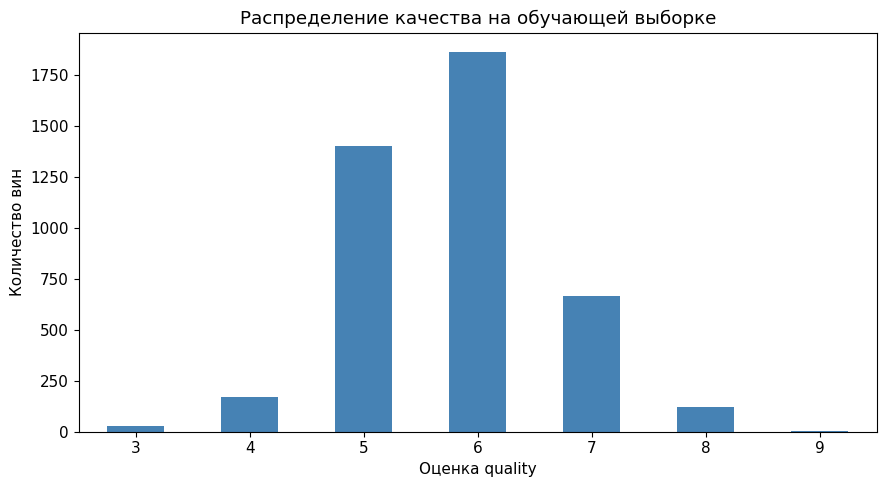

In [5]:
display(train_data.describe().T.round(3))

quality_counts = y_train.value_counts().sort_index()
display(quality_counts.to_frame('Количество на train'))
quality_counts.plot.bar(color='steelblue', rot=0)
plt.xlabel('Оценка quality')
plt.ylabel('Количество вин')
plt.title('Распределение качества на обучающей выборке')
plt.tight_layout()
plt.show()

Преобладают оценки 5 и 6; крайние оценки представлены существенно меньшим числом наблюдений.
Это создаёт предпосылки для менее точного прогноза редких значений `quality`.
Редкие наблюдения сохранены.

Масштабы признаков различаются: плотность близка к единице, содержание общего диоксида серы
измеряется десятками и сотнями. Для сопоставления коэффициентов линейной модели используется стандартизация.
Экстремальные значения сахара и диоксида серы сохранены ввиду отсутствия подтверждения ошибок измерения.

,count,mean,std
is_red,,,
Белое,3186,5.848,0.893
Красное,1070,5.616,0.828


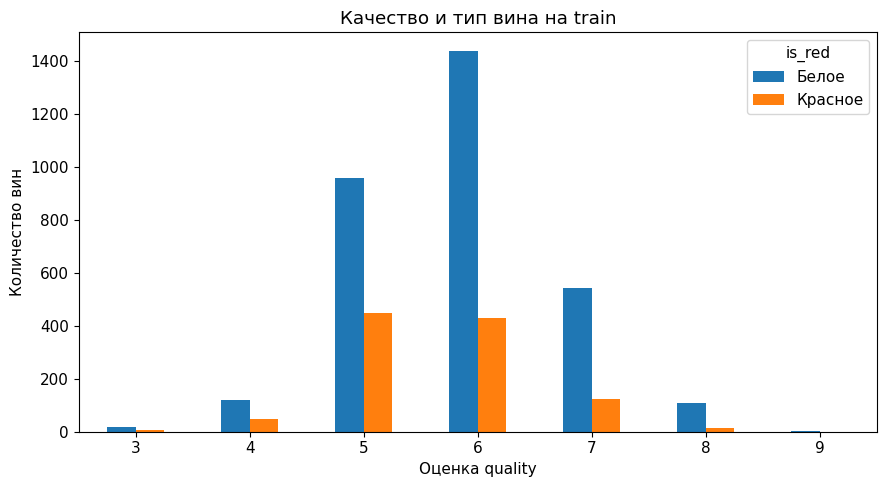

In [6]:
type_summary = train_data.groupby('is_red')['quality'].agg(['count', 'mean', 'std'])
type_summary.index = type_summary.index.map({0: 'Белое', 1: 'Красное'})
display(type_summary.round(3))

pd.crosstab(train_data['quality'], train_data['is_red']).rename(
    columns={0: 'Белое', 1: 'Красное'}
).plot.bar(rot=0)
plt.xlabel('Оценка quality')
plt.ylabel('Количество вин')
plt.title('Качество и тип вина на train')
plt.tight_layout()
plt.show()

На train представлено 3 186 белых и 1 070 красных вин; средние оценки составляют 5.848 и 5.616 соответственно.
Различия групп обосновывают включение признака типа вина, однако не устанавливают причинную связь.
Из-за преобладания белых вин их ошибки имеют больший вес в общей метрике.

,Корреляция с quality
density,-0.324
volatile acidity,-0.263
chlorides,-0.212
is_red,-0.114
fixed acidity,-0.077
residual sugar,-0.060
total sulfur dioxide,-0.049
pH,0.025
free sulfur dioxide,0.054
sulphates,0.054


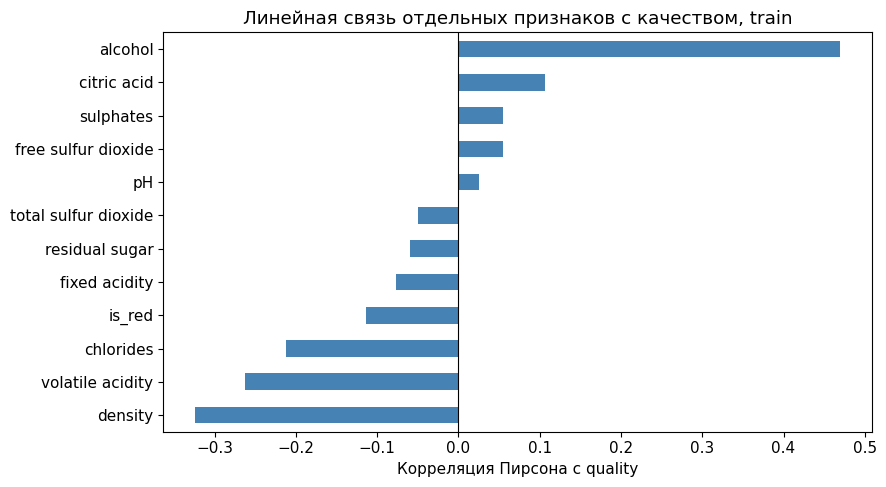

In [7]:
correlations = X_train.corrwith(y_train).sort_values()
display(correlations.to_frame('Корреляция с quality').round(3))
correlations.plot.barh(color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Корреляция Пирсона с quality')
plt.title('Линейная связь отдельных признаков с качеством, train')
plt.tight_layout()
plt.show()

Наиболее выраженная положительная корреляция с `quality` наблюдается у `alcohol` (0.469):
большее содержание алкоголя связано с более высокой оценкой в данной выборке.
У `density` (−0.324) и `volatile acidity` (−0.263) связь отрицательная.
Эти признаки сохранены для моделирования. Признаки со слабой линейной корреляцией также сохранены,
поскольку она не исключает нелинейных и условных зависимостей.

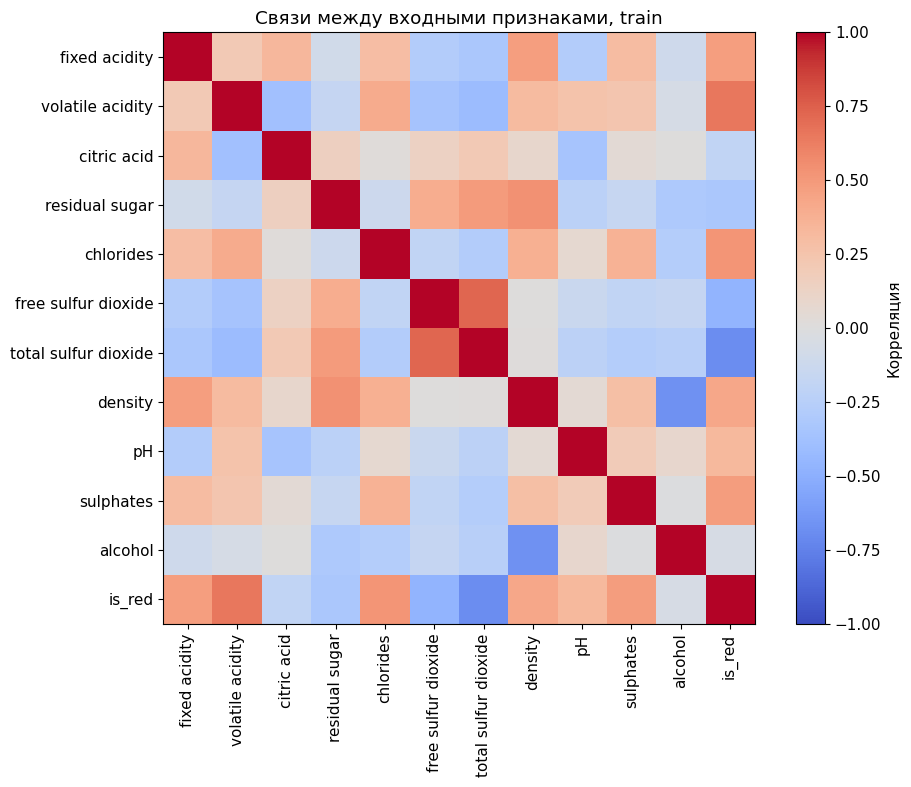

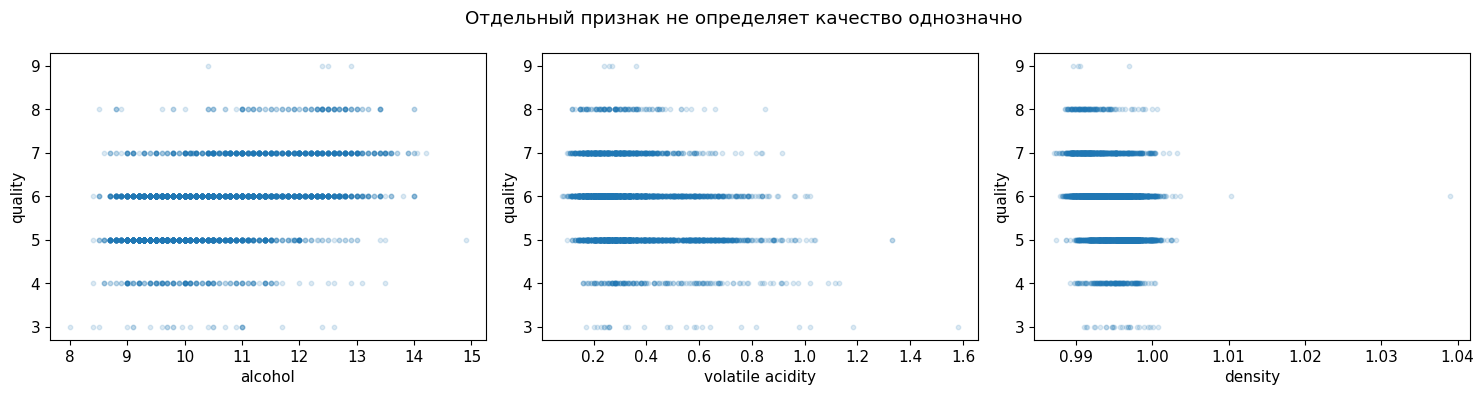

In [8]:
corr_matrix = X_train.corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90)
ax.set_yticks(range(len(corr_matrix)), corr_matrix.columns)
fig.colorbar(image, ax=ax, label='Корреляция')
ax.set_title('Связи между входными признаками, train')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ['alcohol', 'volatile acidity', 'density']):
    ax.scatter(X_train[feature], y_train, s=10, alpha=0.15)
    ax.set_xlabel(feature)
    ax.set_ylabel('quality')
plt.suptitle('Отдельный признак не определяет качество однозначно')
plt.tight_layout()
plt.show()

Между входными признаками присутствуют корреляции, в частности между свободным и общим диоксидом серы,
плотностью и остаточным сахаром. Это учитывается при интерпретации коэффициентов и важностей.
Разброс оценок при одинаковых значениях отдельных признаков указывает на ограниченность
одномерных зависимостей и обосновывает сравнение линейной модели с ансамблями деревьев.

## 4. Метрики и baseline

Для истинных оценок $y_i$ и предсказаний $\hat y_i$ рассчитаны:

$$MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|,$$
$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}.$$

MAE характеризует среднее абсолютное отклонение в баллах качества. RMSE выражается в тех же единицах
и сильнее реагирует на крупные ошибки вследствие возведения отклонений в квадрат.
Различие метрик связано с неоднородностью модулей ошибок; при наличии крупных промахов RMSE заметно выше MAE.
Основной критерий сравнения — минимальный RMSE.

Baseline предсказывает среднее `y_train`: эта константа минимизирует сумму квадратов ошибок,
а следовательно, MSE и RMSE на обучающей выборке.

In [9]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
print(f'Константа baseline: {y_train.mean():.4f}')

Константа baseline: 5.7899


## 5. Обучение и выбор моделей

Обучены `LinearRegression`, `RandomForestRegressor` и `GradientBoostingRegressor`.
Линейная модель включена в `Pipeline` со `StandardScaler` для сопоставимости коэффициентов.
Статистики масштабирования вычисляются внутри каждого обучающего фолда.
Для деревьев стандартизация не применяется.

Проверены четыре конфигурации случайного леса и четыре конфигурации бустинга.
Состав признаков, исходное разбиение и фолды одинаковы для всех вариантов.

In [10]:
candidates = {
    'Baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'RF_300': RandomForestRegressor(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    'RF_500': RandomForestRegressor(
        n_estimators=500, max_features=0.8,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'RF_500_half': RandomForestRegressor(
        n_estimators=500, max_features=0.5,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'RF_500_leaf2': RandomForestRegressor(
        n_estimators=500, max_features=0.8, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'GB_default': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'GB_500_depth3': GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=3,
        min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    'GB_500_depth4': GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=4,
        min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    'GB_regularized': GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        min_samples_leaf=20, subsample=0.8, random_state=RANDOM_STATE
    ),
}

Использована пятикратная кросс-валидация `KFold` с перемешиванием и `random_state=42`.
В таблице приведены средние RMSE и MAE на проверочных фолдах, стандартное отклонение RMSE
между фолдами и средняя обучающая RMSE. Отложенный test в выборе параметров не участвует.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in candidates.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={'RMSE': 'neg_root_mean_squared_error',
                 'MAE': 'neg_mean_absolute_error'},
        return_train_score=True,
        n_jobs=1,
    )
    cv_rows.append({
        'Вариант': name,
        'CV RMSE': -scores['test_RMSE'].mean(),
        'CV MAE': -scores['test_MAE'].mean(),
        'CV std': scores['test_RMSE'].std(),
        'Train RMSE': -scores['train_RMSE'].mean(),
    })

cv_table = pd.DataFrame(cv_rows).set_index('Вариант')
display(cv_table.round(4))

,CV RMSE,CV MAE,CV std,Train RMSE
Вариант,,,,
Baseline,0.8829,0.6969,0.0074,0.8827
Linear Regression,0.7350,0.5666,0.0222,0.7325
RF_300,0.6990,0.5385,0.0158,0.2593
RF_500,0.6959,0.5365,0.0156,0.2577
RF_500_half,0.6933,0.5347,0.0166,0.2570
RF_500_leaf2,0.6958,0.5363,0.0166,0.3315
GB_default,0.7069,0.5489,0.0175,0.6338
GB_500_depth3,0.7088,0.5504,0.0156,0.5736
GB_500_depth4,0.7112,0.5511,0.0165,0.4876


Выбранные варианты: {'Baseline': 'Baseline', 'Linear Regression': 'Linear Regression', 'Random Forest': 'RF_500_half', 'Gradient Boosting': 'GB_regularized'}
Лучшая модель по кросс-валидации: Random Forest


,CV RMSE,CV MAE,CV std,Train RMSE
Baseline,0.8829,0.6969,0.0074,0.8827
Linear Regression,0.7350,0.5666,0.0222,0.7325
Random Forest,0.6933,0.5347,0.0166,0.2570
Gradient Boosting,0.7036,0.5460,0.0201,0.6386


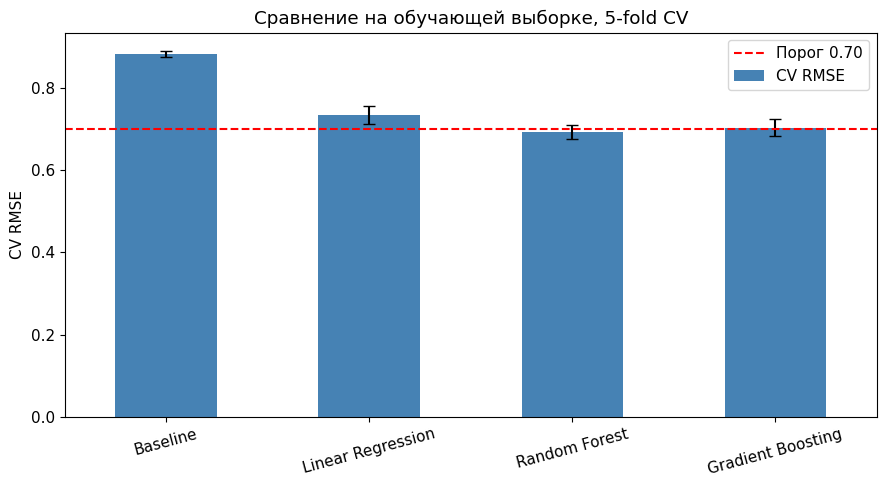

In [12]:
# Выбор конфигураций по минимальному CV RMSE.
selected_variants = {
    'Baseline': 'Baseline',
    'Linear Regression': 'Linear Regression',
    'Random Forest': cv_table.loc[
        ['RF_300', 'RF_500', 'RF_500_half', 'RF_500_leaf2'], 'CV RMSE'
    ].idxmin(),
    'Gradient Boosting': cv_table.loc[
        ['GB_default', 'GB_500_depth3', 'GB_500_depth4', 'GB_regularized'], 'CV RMSE'
    ].idxmin(),
}
selection_table = cv_table.loc[list(selected_variants.values())].copy()
selection_table.index = list(selected_variants)
best_name = selection_table['CV RMSE'].idxmin()

print('Выбранные варианты:', selected_variants)
print('Лучшая модель по кросс-валидации:', best_name)
display(selection_table.round(4))

selection_table['CV RMSE'].plot.bar(
    yerr=selection_table['CV std'], capsize=4, color='steelblue', rot=15
)
plt.axhline(0.70, color='red', linestyle='--', label='Порог 0.70')
plt.ylabel('CV RMSE')
plt.title('Сравнение на обучающей выборке, 5-fold CV')
plt.legend()
plt.tight_layout()
plt.show()

Минимальный средний CV RMSE получен для случайного леса: **0.6933**
(`n_estimators=500`, `max_features=0.5`). Для baseline CV RMSE составляет 0.8829,
для линейной регрессии — 0.7350, для выбранного бустинга — 0.7036.
Различия конфигураций леса невелики относительно межфолдового разброса.

У выбранного леса Train RMSE ≈ 0.257 существенно ниже CV RMSE, что указывает на подгонку под обучение.
У бустинга увеличение глубины до 4 снизило Train RMSE до 0.488, но ухудшило CV RMSE до 0.7112.
Выбран вариант `GB_regularized`: 200 деревьев, `learning_rate=0.05`, глубина 3,
`min_samples_leaf=20`, `subsample=0.8`.
Конфигурации и лучшая модель зафиксированы до оценки на test.

## 6. Итоговое сравнение на тестовой выборке

Выбранные конфигурации обучены на всём train и оценены на общей отложенной тестовой выборке.

In [13]:
fitted_models = {}
test_predictions = {}
test_rows = []

for name, variant in selected_variants.items():
    model = clone(candidates[variant])
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    fitted_models[name] = model
    test_predictions[name] = prediction
    test_rows.append({
        'Модель': name,
        'RMSE': root_mean_squared_error(y_test, prediction),
        'MAE': mean_absolute_error(y_test, prediction),
    })

results = pd.DataFrame(test_rows).set_index('Модель')
display(results.round(4))

baseline_rmse = results.loc['Baseline', 'RMSE']
for name in results.index:
    if name != 'Baseline':
        print(f"{name} лучше baseline: {results.loc[name, 'RMSE'] < baseline_rmse}")

best_rmse = results.loc[best_name, 'RMSE']
print(f'Модель, выбранная по CV: {best_name}')
print(f'Её test RMSE: {best_rmse:.4f}; требование RMSE < 0.70: {best_rmse < 0.70}')
assert best_rmse < 0.70, 'Локальный порог RMSE < 0.70 не достигнут.'

,RMSE,MAE
Модель,,
Baseline,0.8676,0.6942
Linear Regression,0.7208,0.5602
Random Forest,0.6584,0.5060
Gradient Boosting,0.6808,0.5241


Linear Regression лучше baseline: True
Random Forest лучше baseline: True
Gradient Boosting лучше baseline: True
Модель, выбранная по CV: Random Forest
Её test RMSE: 0.6584; требование RMSE < 0.70: True


Все обученные модели превзошли baseline по обеим метрикам. Случайный лес получил
**RMSE = 0.6584, MAE = 0.5060**, снизив RMSE относительно baseline на 24.1%.
Локальный порог RMSE < 0.70 выполнен также градиентным бустингом (0.6808).
Линейная регрессия с RMSE = 0.7208 порога не достигла.

Преимущество ансамблей согласуется с CV и возможностью учитывать нелинейные зависимости
и сочетания признаков. В данном эксперименте усреднение разнообразных деревьев леса
оказалось эффективнее выбранной конфигурации бустинга.
Результаты относятся к локальному test; качество на скрытой выборке преподавателя неизвестно.

## 7. Коэффициенты и важность признаков

### Линейная регрессия

Коэффициенты рассчитаны на стандартизованных признаках: их величины соответствуют изменению прогноза
при увеличении признака на одно стандартное отклонение train при фиксированных остальных признаках.

,Коэффициент
alcohol,0.2918
density,-0.2528
volatile acidity,-0.2255
residual sugar,0.2192
is_red,0.1198
sulphates,0.1196
free sulfur dioxide,0.1061
total sulfur dioxide,-0.1004
pH,0.0807
fixed acidity,0.0790


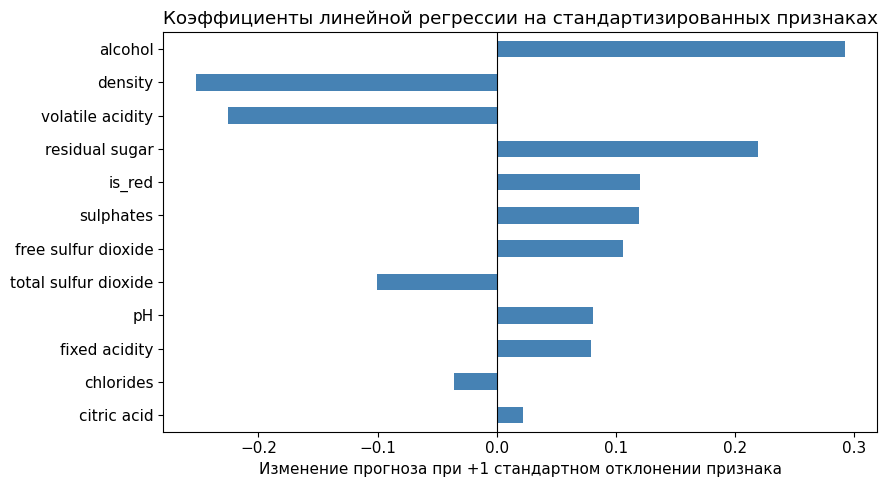

In [14]:
linear_model = fitted_models['Linear Regression'].named_steps['linearregression']
coefficients = pd.Series(linear_model.coef_, index=X_train.columns)
coefficient_order = coefficients.abs().sort_values().index

display(coefficients.loc[coefficient_order[::-1]].to_frame('Коэффициент').round(4))
coefficients.loc[coefficient_order].plot.barh(color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Изменение прогноза при +1 стандартном отклонении признака')
plt.title('Коэффициенты линейной регрессии на стандартизированных признаках')
plt.tight_layout()
plt.show()

Наибольшие модули коэффициентов имеют `alcohol` (+0.292), `density` (−0.253),
`volatile acidity` (−0.225) и `residual sugar` (+0.219).
Алкоголь, плотность и летучая кислотность согласуются по направлению связи с результатами корреляционного анализа.

Слабая отдельная корреляция сахара сочетается с относительно крупным коэффициентом в многомерной модели.
У `is_red` знак коэффициента противоположен знаку корреляции.
Эти различия объяснимы учётом остальных, в том числе взаимосвязанных, признаков.
Коэффициенты характеризуют условные связи внутри модели и не устанавливают причинность.

### Случайный лес и градиентный бустинг

Сопоставлены встроенные важности `feature_importances_`, основанные на уменьшении ошибки при разбиениях деревьев.

,Random Forest,Gradient Boosting
alcohol,0.2186,0.4447
volatile acidity,0.1077,0.1563
density,0.0956,0.0229
free sulfur dioxide,0.0931,0.0956
sulphates,0.0776,0.0739
total sulfur dioxide,0.0747,0.0458
chlorides,0.0709,0.0245
pH,0.0695,0.0373
residual sugar,0.0657,0.0361
citric acid,0.0633,0.0278


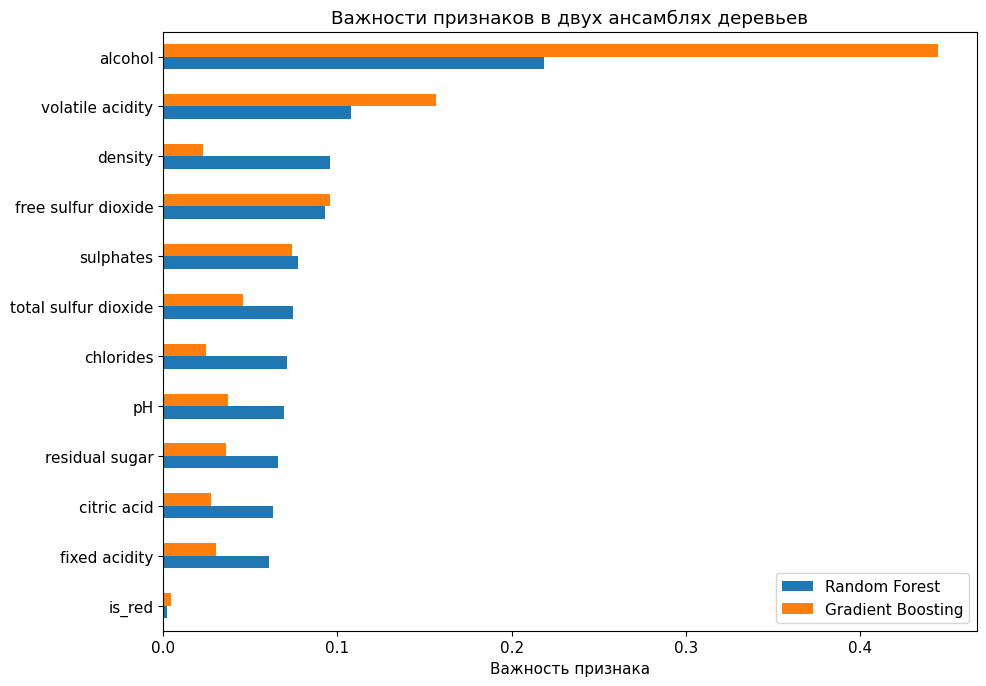

Random Forest — топ-5: alcohol, volatile acidity, density, free sulfur dioxide, sulphates
Gradient Boosting — топ-5: alcohol, volatile acidity, free sulfur dioxide, sulphates, total sulfur dioxide
Линейная модель — топ-5 по модулю: alcohol, density, volatile acidity, residual sugar, is_red
Корреляция — топ-5 по модулю: alcohol, density, volatile acidity, chlorides, is_red


In [15]:
importances = pd.DataFrame({
    'Random Forest': fitted_models['Random Forest'].feature_importances_,
    'Gradient Boosting': fitted_models['Gradient Boosting'].feature_importances_,
}, index=X_train.columns)

importance_order = importances['Random Forest'].sort_values().index
display(importances.loc[importance_order[::-1]].round(4))
importances.loc[importance_order].plot.barh(figsize=(10, 7))
plt.xlabel('Важность признака')
plt.title('Важности признаков в двух ансамблях деревьев')
plt.tight_layout()
plt.show()

for name in importances.columns:
    print(name, '— топ-5:', ', '.join(importances[name].nlargest(5).index))

print('Линейная модель — топ-5 по модулю:', ', '.join(coefficients.abs().nlargest(5).index))
print('Корреляция — топ-5 по модулю:', ', '.join(correlations.abs().nlargest(5).index))

| Метод | Ведущие признаки |
|---|---|
| Корреляция по модулю | alcohol, density, volatile acidity, chlorides, is_red |
| Линейная модель, модуль коэффициента | alcohol, density, volatile acidity, residual sugar, is_red |
| Random Forest | alcohol, volatile acidity, density, free sulfur dioxide, sulphates |
| Gradient Boosting | alcohol, volatile acidity, free sulfur dioxide, sulphates, total sulfur dioxide |

Оба ансамбля выделяют `alcohol` и `volatile acidity`, что согласуется с первичным анализом.
Важность алкоголя составляет 0.219 у леса и 0.445 у бустинга.
Лес сильнее использует плотность; бустинг может чаще опираться на связанные с ней характеристики.
Свободный диоксид серы входит в топ-5 обоих ансамблей при слабой отдельной корреляции с качеством (0.054),
что допускает наличие условных или нелинейных зависимостей.

Рейтинги зависят от модели и распределения информации между связанными признаками.
Встроенные важности могут быть смещены в пользу признаков с большим числом возможных порогов
([документация sklearn](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html)).
Важность не определяет направление связи и не доказывает причинность:
наблюдательные данные не позволяют установить результат независимого изменения одного компонента вина.

## 8. Анализ ошибок

Проанализированы тестовые предсказания случайного леса, выбранного по CV.
Ошибка определена как $\hat y-y$: положительное значение соответствует завышению оценки.

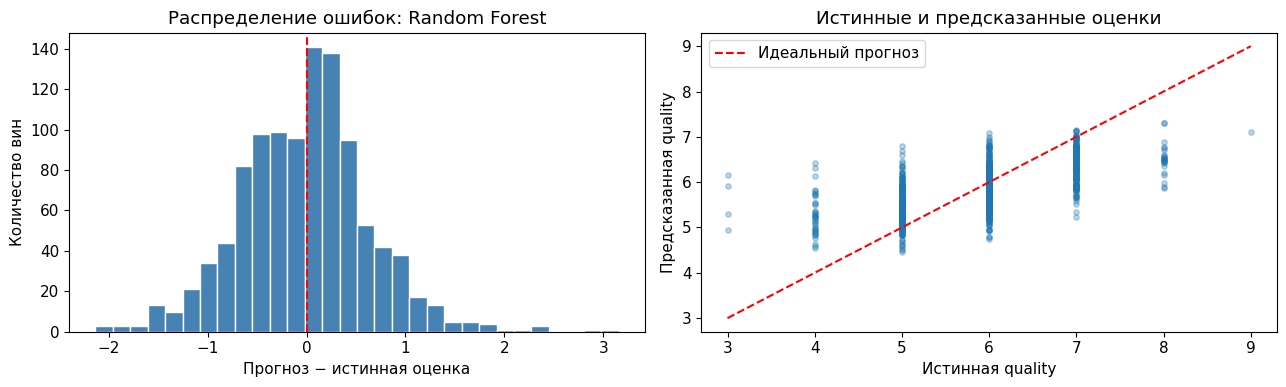

Средняя ошибка со знаком: -0.0156
Доля ошибок не больше 1 балла: 88.5%


In [16]:
best_prediction = test_predictions[best_name]
errors = X_test.copy()
errors['quality_true'] = y_test
errors['quality_pred'] = best_prediction
errors['error'] = errors['quality_pred'] - errors['quality_true']
errors['abs_error'] = errors['error'].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(errors['error'], bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_xlabel('Прогноз − истинная оценка')
axes[0].set_ylabel('Количество вин')
axes[0].set_title(f'Распределение ошибок: {best_name}')

axes[1].scatter(y_test, best_prediction, s=15, alpha=0.3)
axes[1].plot([3, 9], [3, 9], color='red', linestyle='--', label='Идеальный прогноз')
axes[1].set_xlabel('Истинная quality')
axes[1].set_ylabel('Предсказанная quality')
axes[1].set_title('Истинные и предсказанные оценки')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Средняя ошибка со знаком: {errors['error'].mean():.4f}")
print(f"Доля ошибок не больше 1 балла: {(errors['abs_error'] <= 1).mean():.1%}")

Средняя ошибка со знаком составляет −0.0156; выраженного общего смещения не наблюдается.
Для 88.5% тестовых объектов абсолютная ошибка не превышает одного балла.
При этом присутствуют крупные промахи в хвостах распределения.
На диаграмме истинных и предсказанных оценок заметны завышение низких оценок и занижение высоких.

,Количество test,Количество train,Средний прогноз,Средняя ошибка,MAE,RMSE
quality,,,,,,
3,4,26,5.5820,2.5820,2.5820,2.6263
4,38,168,5.2837,1.2837,1.2837,1.3605
5,348,1404,5.4128,0.4128,0.4433,0.5574
6,458,1865,5.8637,-0.1363,0.3643,0.4480
7,190,666,6.3798,-0.6202,0.6262,0.7297
8,25,123,6.5096,-1.4904,1.4904,1.5291
9,1,4,7.1060,-1.8940,1.8940,1.8940


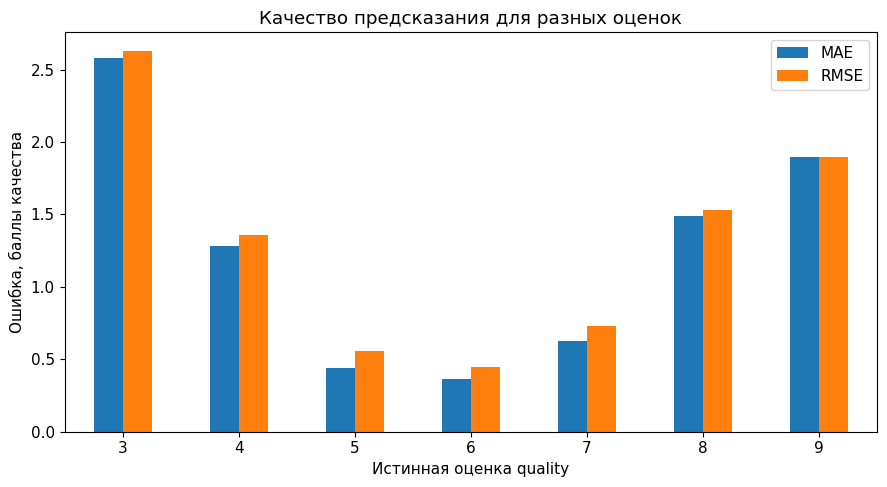

In [17]:
quality_rows = []
for quality, part in errors.groupby('quality_true'):
    quality_rows.append({
        'quality': quality,
        'Количество test': len(part),
        'Количество train': int((y_train == quality).sum()),
        'Средний прогноз': part['quality_pred'].mean(),
        'Средняя ошибка': part['error'].mean(),
        'MAE': mean_absolute_error(part['quality_true'], part['quality_pred']),
        'RMSE': root_mean_squared_error(part['quality_true'], part['quality_pred']),
    })
errors_by_quality = pd.DataFrame(quality_rows).set_index('quality')
display(errors_by_quality.round(4))

errors_by_quality[['MAE', 'RMSE']].plot.bar(rot=0)
plt.xlabel('Истинная оценка quality')
plt.ylabel('Ошибка, баллы качества')
plt.title('Качество предсказания для разных оценок')
plt.tight_layout()
plt.show()

Наименьшие MAE получены для частых оценок 5 и 6: 0.443 и 0.364 соответственно.
При истинной оценке 3 средний прогноз составляет 5.582; при оценке 8 — 6.510.
Таким образом, крайние оценки смещаются к середине диапазона.

В train содержится лишь 26 наблюдений с оценкой 3 и 4 с оценкой 9.
Нехватка примеров и усреднение прогнозов могут объяснять ухудшение качества на редких оценках.
Дополнительные причины — неполнота химических признаков и вариативность экспертных оценок.
На test оценки 3 и 9 представлены четырьмя и одним объектом соответственно,
поэтому групповые метрики для них неустойчивы.

In [18]:
type_rows = []
for is_red, part in errors.groupby('is_red'):
    type_rows.append({
        'Тип': 'Красное' if is_red == 1 else 'Белое',
        'Количество': len(part),
        'RMSE': root_mean_squared_error(part['quality_true'], part['quality_pred']),
        'MAE': mean_absolute_error(part['quality_true'], part['quality_pred']),
    })
display(pd.DataFrame(type_rows).set_index('Тип').round(4))

,Количество,RMSE,MAE
Тип,,,
Белое,775,0.6748,0.5149
Красное,289,0.6122,0.4820


RMSE на белом вине составляет 0.6748, на красном — 0.6122.
Различие относится к данному разбиению; группы различаются размером и распределением оценок.

### Наибольшие ошибки

Для пяти крупнейших промахов приведены характеристики объектов.
Три из них дополнительно сопоставлены с диапазоном 5–95-го процентилей обучающих признаков.

In [19]:
worst = errors.nlargest(5, 'abs_error')
display(worst.round(4))

train_lower = X_train.quantile(0.05)
train_upper = X_train.quantile(0.95)
for index, row in worst.head(3).iterrows():
    features = row[X_train.columns]
    unusual = features.index[
        (features < train_lower) | (features > train_upper)
    ].tolist()
    direction = 'завышена' if row['error'] > 0 else 'занижена'
    print(f"Строка {index}: true={row['quality_true']:.0f}, "
          f"pred={row['quality_pred']:.3f}, оценка {direction}.")
    print('  Таких оценок на train:', int((y_train == row['quality_true']).sum()))
    print('  Признаки за пределами 5–95% train:', ', '.join(unusual) or 'нет')

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red,quality_true,quality_pred,error,abs_error
4151,6.2,0.23,0.35,0.7,0.051,24.0,111.0,0.9916,3.37,0.43,11.0,0,3,6.154,3.154,3.154
1729,7.1,0.32,0.32,11.0,0.038,16.0,66.0,0.9937,3.24,0.40,11.5,0,3,5.926,2.926,2.926
4404,6.5,0.32,0.48,8.0,0.026,18.0,88.0,0.9914,3.22,0.79,12.7,0,4,6.428,2.428,2.428
2057,7.4,0.17,0.40,5.5,0.037,34.0,161.0,0.9935,3.05,0.62,11.5,0,4,6.306,2.306,2.306
718,10.4,0.44,0.42,1.5,0.145,34.0,48.0,0.9983,3.38,0.86,9.9,1,3,5.294,2.294,2.294


Строка 4151: true=3, pred=6.154, оценка завышена.
  Таких оценок на train: 26
  Признаки за пределами 5–95% train: residual sugar
Строка 1729: true=3, pred=5.926, оценка завышена.
  Таких оценок на train: 26
  Признаки за пределами 5–95% train: нет
Строка 4404: true=4, pred=6.428, оценка завышена.
  Таких оценок на train: 168
  Признаки за пределами 5–95% train: chlorides


| Индекс | Истинная оценка | Прогноз | Ошибка | Возможное объяснение |
|---|---:|---:|---:|---|
| 4151 | 3 | 6.154 | +3.154 | Редкая оценка; сахар 0.7 ниже 5-го процентиля train. Алкоголь 11.0 и невысокая летучая кислотность могут направлять прогноз к более высокой оценке. |
| 1729 | 3 | 5.926 | +2.926 | Отдельные признаки входят в диапазон 5–95%. Возможны редкое сочетание обычных значений, неучтённые свойства или особенности экспертной оценки. |
| 4404 | 4 | 6.428 | +2.428 | Хлориды 0.026 ниже 5-го процентиля; алкоголь 12.7 относительно высок. Перенос положительной связи алкоголя с качеством может приводить к завышению редкой низкой оценки. |

Индексы относятся к таблице после удаления повторов. Приведённые объяснения являются гипотезами.
Крупные ошибки не служат основанием для исключения объектов; все они учтены в итоговых метриках.
После анализа ошибок параметры моделей не изменялись.

## 9. Заключение

Выполнены подготовка Wine Quality, исследовательский анализ, сравнение константного baseline
и трёх регрессионных моделей, анализ коэффициентов, важности признаков и ошибок.

Случайный лес с 500 деревьями и `max_features=0.5` выбран по минимальному CV RMSE (0.6933).
На локальном test получены **RMSE = 0.6584** и **MAE = 0.5060**;
RMSE ниже baseline на **24.1%** и удовлетворяет локальному порогу 0.70.

Алкоголь и летучая кислотность устойчиво выделяются разными методами анализа.
Основное ограничение модели — завышение редких низких оценок и занижение высоких.
Результат на единой скрытой выборке преподавателя требует отдельной проверки.